# Notebook 04: Spatial, Predictor and Split EDA

This notebook examines the auxiliary predictor, spatial station relationships and chronological modelling split. The aim is to support later feature engineering decisions, including temperature use, neighbouring station features, inverse-distance weighting and leakage-aware train-validation-test splitting.

## Step 1: Setup and load datasets

Loads the processed long-format panel and station metadata saved by NB01.

In [1]:
# ============================================================
# Notebook 04: Spatial, Predictor and Split EDA
# Step 1: Setup and load final processed datasets
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

# This notebook starts from the processed outputs of Notebook 01.
# Using processed files keeps this notebook focused on predictor, spatial and split analysis,
# rather than repeating raw data parsing.
DATA_DIR = Path.home() / "Desktop" / "DISSERTATION" / "Codes" / "data" / "processed"

panel_path = DATA_DIR / "selected_pm25_temperature_panel.csv"
metadata_path = DATA_DIR / "selected_station_metadata.csv"
pm25_wide_path = DATA_DIR / "selected_pm25_wide_panel.csv"
temperature_wide_path = DATA_DIR / "selected_temperature_wide_panel.csv"

panel = pd.read_csv(panel_path)
metadata = pd.read_csv(metadata_path)
pm25_wide = pd.read_csv(pm25_wide_path)
temperature_wide = pd.read_csv(temperature_wide_path)

# Datetime conversion is needed because later split checks and temporal summaries
# depend on year-based and time-based filtering.
panel["Datetime"] = pd.to_datetime(panel["Datetime"])
pm25_wide["Datetime"] = pd.to_datetime(pm25_wide["Datetime"])
temperature_wide["Datetime"] = pd.to_datetime(temperature_wide["Datetime"])

print("Main panel shape:", panel.shape)
print("Metadata shape:", metadata.shape)
print("PM2.5 wide shape:", pm25_wide.shape)
print("Temperature wide shape:", temperature_wide.shape)

display(panel.head())
display(metadata)

Main panel shape: (219120, 5)
Metadata shape: (5, 7)
PM2.5 wide shape: (43824, 6)
Temperature wide shape: (43824, 6)


,Station,Datetime,RawYear,PM25,Temperature
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2


,Station,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority
0,London Bexley,51.466030,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
1,London Harlington,51.488790,-0.441614,Urban Industrial,Greater London,Greater London Urban Area,Hillingdon
2,London Honor Oak Park,51.449674,-0.037418,Urban Background,Greater London,Greater London Urban Area,Lewisham
3,London Marylebone Road,51.522530,-0.154611,Urban Traffic,Greater London,Greater London Urban Area,Westminster
4,London N. Kensington,51.521050,-0.213419,Urban Background,Greater London,Greater London Urban Area,Kensington


## Step 2: Add temporal features and station metadata

Adds time-based columns and merges station coordinates into a working EDA copy.

In [2]:
# ============================================================
# Step 2: Add temporal features and station metadata
# ============================================================

# A working EDA copy is created so metadata and time features can be added
# without modifying the original processed modelling panel.
eda = panel.copy()

# Time features are kept because predictor behaviour and train/test checks
# may differ by month, season or year.
eda["Year"] = eda["Datetime"].dt.year
eda["Month"] = eda["Datetime"].dt.month
eda["Hour"] = eda["Datetime"].dt.hour

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

eda["Season"] = eda["Month"].apply(assign_season)

# Metadata is joined because spatial and site-type information is needed
# to interpret station differences and construct neighbour-based features later.
eda = eda.merge(
    metadata,
    on="Station",
    how="left"
)

# This check confirms that every row successfully received station metadata.
missing_metadata_rows = eda["Latitude"].isna().sum()

print("EDA shape after metadata merge:", eda.shape)
print("Rows with missing metadata:", missing_metadata_rows)

display(eda.head())

assert missing_metadata_rows == 0, "Some rows did not match station metadata"

EDA shape after metadata merge: (219120, 15)
Rows with missing metadata: 0


,Station,Datetime,RawYear,PM25,Temperature,Year,Month,Hour,Season,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2,2021,1,1,Winter,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9,2021,1,2,Winter,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3,2021,1,3,Winter,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8,2021,1,4,Winter,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2,2021,1,5,Winter,51.46603,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley


## Step 3: Temperature predictor overview

This step examines temperature as an auxiliary predictor for PM2.5 imputation. Temperature is not the target variable, but it may provide useful meteorological context for machine-learning and spatio-temporal models.

The aim is to check whether temperature is available, plausible and variable enough to support later modelling. Negative values are not treated as errors because temperature is measured in degrees Celsius.

In [3]:
# ============================================================
# Step 3: Temperature predictor overview
# ============================================================

# Temperature is assessed here because it is planned as an auxiliary predictor.
# Its usefulness depends partly on whether it has good availability and plausible values.
temperature_observed = eda["Temperature"].dropna()

temperature_summary = pd.DataFrame({
    "Metric": [
        "Valid temperature observations",
        "Missing temperature observations",
        "Temperature capture (%)",
        "Mean temperature",
        "Median temperature",
        "Standard deviation",
        "Minimum temperature",
        "Maximum temperature",
        "Negative temperature observations"
    ],
    "Value": [
        eda["Temperature"].notna().sum(),
        eda["Temperature"].isna().sum(),
        round(eda["Temperature"].notna().mean() * 100, 2),
        round(temperature_observed.mean(), 2),
        round(temperature_observed.median(), 2),
        round(temperature_observed.std(), 2),
        round(temperature_observed.min(), 2),
        round(temperature_observed.max(), 2),
        (eda["Temperature"] < 0).sum()
    ]
})

display(temperature_summary)

,Metric,Value
0,Valid temperature observations,214920.00
1,Missing temperature observations,4200.00
2,Temperature capture (%),98.08
3,Mean temperature,10.46
4,Median temperature,10.30
5,Standard deviation,6.08
6,Minimum temperature,-7.50
7,Maximum temperature,31.90
8,Negative temperature observations,8560.00


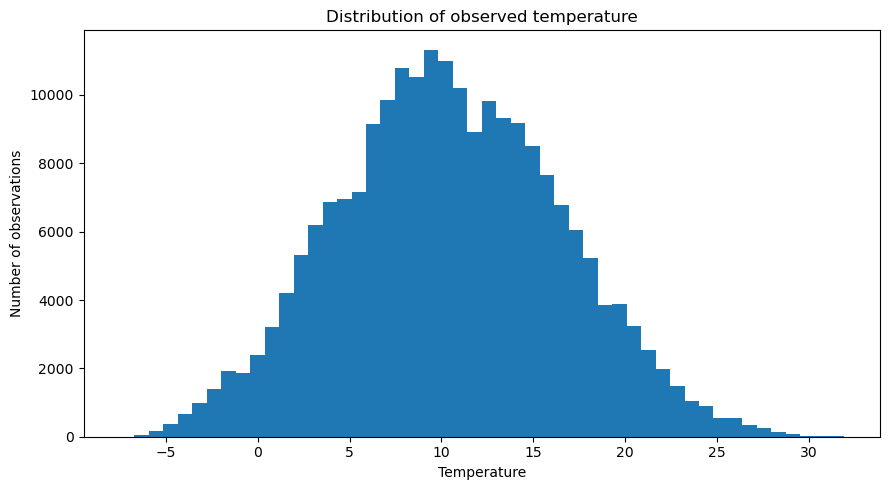

In [4]:
# ============================================================
# Step 3.1: Visualise temperature distribution
# ============================================================

# The temperature distribution is checked to confirm that the auxiliary predictor
# has a realistic range and enough variability to provide meteorological context.
plt.figure(figsize=(9, 5))

plt.hist(
    temperature_observed,
    bins=50
)

plt.xlabel("Temperature")
plt.ylabel("Number of observations")
plt.title("Distribution of observed temperature")

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# Step 3.2: Temperature by season
# ============================================================

# Seasonal temperature patterns are expected and help confirm that the variable
# captures meaningful meteorological variation rather than behaving like noise.
season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_temperature_summary = (
    eda.groupby("Season")
    .agg(
        Observed_temperature=("Temperature", lambda x: x.notna().sum()),
        Mean_temperature=("Temperature", "mean"),
        Median_temperature=("Temperature", "median"),
        Min_temperature=("Temperature", "min"),
        Max_temperature=("Temperature", "max")
    )
    .reset_index()
)

season_temperature_summary["Season"] = pd.Categorical(
    season_temperature_summary["Season"],
    categories=season_order,
    ordered=True
)

season_temperature_summary = season_temperature_summary.sort_values("Season")

numeric_cols = ["Mean_temperature", "Median_temperature", "Min_temperature", "Max_temperature"]
season_temperature_summary[numeric_cols] = season_temperature_summary[numeric_cols].round(2)

display(season_temperature_summary)

,Season,Observed_temperature,Mean_temperature,Median_temperature,Min_temperature,Max_temperature
3,Winter,53160,4.90,5.1,-7.5,14.5
1,Spring,54240,8.94,8.7,-4.3,25.8
2,Summer,54600,16.55,16.2,4.1,31.9
0,Autumn,52920,11.31,11.4,-3.9,30.6


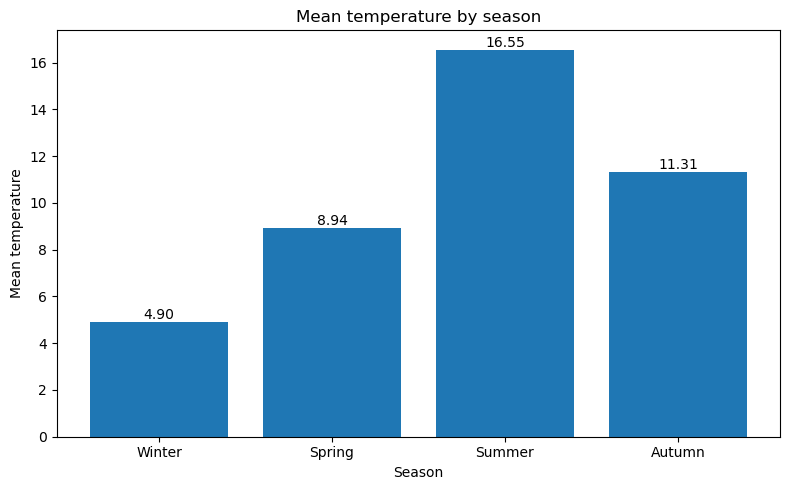

In [6]:
# ============================================================
# Step 3.3: Visualise mean temperature by season
# ============================================================

# This figure checks whether temperature follows the expected seasonal pattern.
# A clear seasonal pattern supports keeping temperature as a meaningful predictor.
plt.figure(figsize=(8, 5))

bars = plt.bar(
    season_temperature_summary["Season"].astype(str),
    season_temperature_summary["Mean_temperature"]
)

plt.xlabel("Season")
plt.ylabel("Mean temperature")
plt.title("Mean temperature by season")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# Step 3.4: Check identical modelled temperature series
# ============================================================

# This check tests whether the modelled temperature series for Marylebone Road
# and N. Kensington are identical. This matters because identical temperature
# inputs cannot help distinguish these two nearby stations in later models.
temperature_pair = temperature_wide[
    ["London Marylebone Road", "London N. Kensington"]
].copy()

both_observed = temperature_pair.dropna()

same_values = (
    both_observed["London Marylebone Road"]
    == both_observed["London N. Kensington"]
).all()

same_missing_pattern = (
    temperature_pair["London Marylebone Road"].isna()
    == temperature_pair["London N. Kensington"].isna()
).all()

print("Marylebone Road and N. Kensington temperature check:")
print(f"Rows where both temperature values are observed: {len(both_observed):,}")
print(f"Observed values identical: {same_values}")
print(f"Missing pattern identical: {same_missing_pattern}")

Marylebone Road and N. Kensington temperature check:
Rows where both temperature values are observed: 42,984
Observed values identical: True
Missing pattern identical: True


### Step 3 interpretation
Temperature has high availability in the final dataset, with 98.08% capture. Its range from -7.5°C to 31.9°C is plausible for London, and negative values are retained because Celsius temperatures can fall below zero.

An additional check showed that the modelled temperature series for London Marylebone Road and London N. Kensington are identical where both values are observed, with the same missing-value pattern. This suggests that temperature provides useful temporal meteorological context, but it does not help distinguish this specific nearby station pair.

The seasonal pattern is also realistic, with the lowest mean temperature in winter and the highest in summer. This supports the use of temperature as a meaningful auxiliary predictor rather than a random or unreliable variable.

However, availability and plausibility alone do not prove that temperature is useful for PM2.5 imputation. The next step therefore examines the relationship between temperature and PM2.5.

## Step 4: PM2.5-temperature relationship

This step examines the relationship between PM2.5 and temperature. Temperature is planned as an auxiliary predictor, so it is important to check whether it contains useful information related to PM2.5 variation.

The aim is not to prove that temperature alone explains PM2.5, because air pollution depends on many factors. Instead, this analysis checks whether temperature provides meteorological context that may support machine-learning and spatio-temporal imputation models.

In [8]:
# ============================================================
# Step 4: Overall PM2.5-temperature correlation
# ============================================================

# Only rows where both PM2.5 and temperature are observed are used.
# This avoids calculating correlation from incomplete pairs.
pm25_temp_observed = eda[["PM25", "Temperature"]].dropna()

# Correlation gives a simple first check of the linear relationship between PM2.5 and temperature.
# This does not capture all nonlinear effects, but it helps assess whether temperature may be informative.
overall_corr = pm25_temp_observed["PM25"].corr(pm25_temp_observed["Temperature"])

print("Overall PM2.5-temperature correlation:", round(overall_corr, 3))
print("Rows used:", len(pm25_temp_observed))

Overall PM2.5-temperature correlation: -0.223
Rows used: 209918


In [9]:
# ============================================================
# Step 4.1: PM2.5-temperature correlation by station
# ============================================================

# Station-level correlations are checked because the PM2.5-temperature relationship
# may differ between traffic, background, suburban and industrial monitoring sites.
# This helps decide whether station-specific modelling behaviour should be expected.

station_temp_corr = (
    eda.dropna(subset=["PM25", "Temperature"])
    .groupby(["Station", "SiteType"])
    .apply(lambda x: x["PM25"].corr(x["Temperature"]))
    .reset_index(name="PM25_temperature_correlation")
)

station_temp_corr["PM25_temperature_correlation"] = (
    station_temp_corr["PM25_temperature_correlation"].round(3)
)

display(station_temp_corr)

,Station,SiteType,PM25_temperature_correlation
0,London Bexley,Suburban Background,-0.241
1,London Harlington,Urban Industrial,-0.220
2,London Honor Oak Park,Urban Background,-0.238
3,London Marylebone Road,Urban Traffic,-0.187
4,London N. Kensington,Urban Background,-0.248


In [10]:
# ============================================================
# Step 4.2: PM2.5-temperature correlation by season
# ============================================================

# Seasonal correlations are useful because the relationship between temperature and PM2.5
# may not be constant across the year.
# This matters because models may perform differently in winter, spring, summer and autumn.

season_temp_corr = (
    eda.dropna(subset=["PM25", "Temperature"])
    .groupby("Season")
    .apply(lambda x: x["PM25"].corr(x["Temperature"]))
    .reset_index(name="PM25_temperature_correlation")
)

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_temp_corr["Season"] = pd.Categorical(
    season_temp_corr["Season"],
    categories=season_order,
    ordered=True
)

season_temp_corr = season_temp_corr.sort_values("Season")
season_temp_corr["PM25_temperature_correlation"] = (
    season_temp_corr["PM25_temperature_correlation"].round(3)
)

display(season_temp_corr)

,Season,PM25_temperature_correlation
3,Winter,-0.460
1,Spring,-0.140
2,Summer,0.041
0,Autumn,-0.030


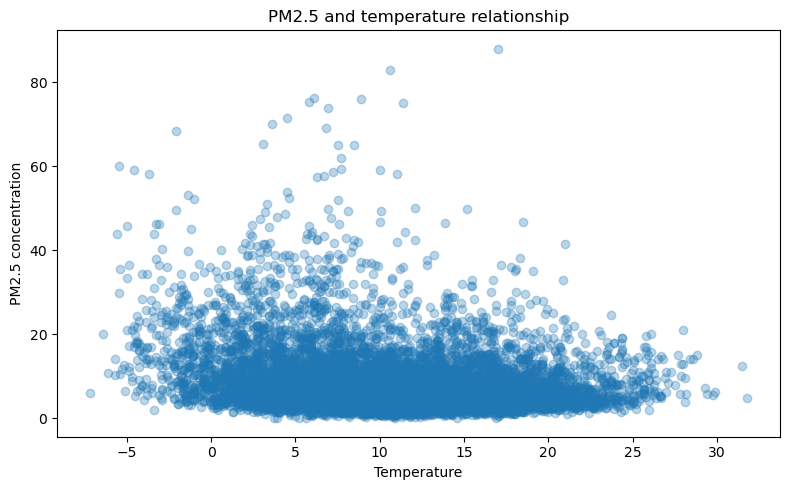

In [11]:
# ============================================================
# Step 4.3: Visualise PM2.5-temperature relationship
# ============================================================

# A scatter plot provides a visual check of whether PM2.5 changes with temperature.
# A sample is used because plotting all 200k+ observations would make the figure crowded
# and less useful for interpretation.

scatter_sample = (
    eda.dropna(subset=["PM25", "Temperature"])
    .sample(n=10000, random_state=42)
)

plt.figure(figsize=(8, 5))

plt.scatter(
    scatter_sample["Temperature"],
    scatter_sample["PM25"],
    alpha=0.3
)

plt.xlabel("Temperature")
plt.ylabel("PM2.5 concentration")
plt.title("PM2.5 and temperature relationship")

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# Step 4.4: Mean PM2.5 by temperature bin
# ============================================================

# Temperature bins make the relationship easier to interpret than a dense scatter plot.
# This shows whether average PM2.5 tends to increase or decrease across temperature ranges.

temp_bin_data = eda.dropna(subset=["PM25", "Temperature"]).copy()

temp_bin_data["Temperature_bin"] = pd.cut(
    temp_bin_data["Temperature"],
    bins=[-10, 0, 5, 10, 15, 20, 25, 35],
    include_lowest=True
)

temp_bin_summary = (
    temp_bin_data.groupby("Temperature_bin")
    .agg(
        Observations=("PM25", "size"),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

temp_bin_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]] = (
    temp_bin_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]].round(2)
)

display(temp_bin_summary)

C:\Users\Msi\AppData\Local\Temp\ipykernel_7848\1284867665.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp_bin_data.groupby("Temperature_bin")


,Temperature_bin,Observations,Mean_PM25,Median_PM25,P95_PM25
0,"(-10.001, 0.0]",8497,15.61,13.02,35.09
1,"(0.0, 5.0]",31872,11.13,8.18,30.00
2,"(5.0, 10.0]",61256,8.87,6.70,23.50
3,"(10.0, 15.0]",59674,7.06,5.66,17.00
4,"(15.0, 20.0]",35778,7.36,5.66,18.69
5,"(20.0, 25.0]",11076,7.45,5.93,17.66
6,"(25.0, 35.0]",1765,9.62,8.96,19.00


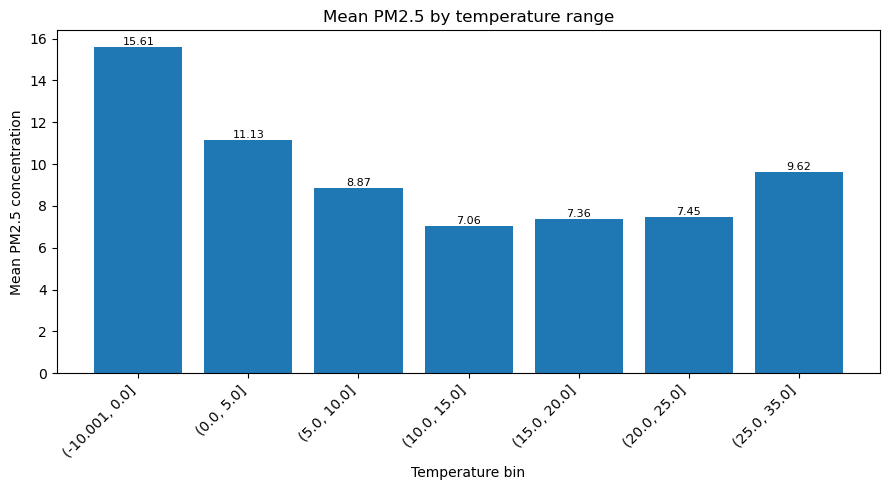

In [13]:
# ============================================================
# Step 4.5: Visualise mean PM2.5 by temperature bin
# ============================================================

# This figure summarises the average PM2.5 level across temperature ranges.
# It helps decide whether temperature should be retained as a simple meteorological predictor.

plt.figure(figsize=(9, 5))

bars = plt.bar(
    temp_bin_summary["Temperature_bin"].astype(str),
    temp_bin_summary["Mean_PM25"]
)

plt.xlabel("Temperature bin")
plt.ylabel("Mean PM2.5 concentration")
plt.title("Mean PM2.5 by temperature range")

plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Step 4 interpretation

The PM2.5-temperature relationship is weakly negative overall, with an overall correlation of -0.223. This suggests that higher temperatures are generally associated with lower PM2.5 concentrations, but temperature alone does not strongly explain PM2.5 variation.

The relationship differs by season. The strongest negative correlation appears in winter, while the relationship is much weaker in spring, summer and autumn. Temperature-bin results also show higher mean PM2.5 during colder temperature ranges, especially below 0°C.

These results support using temperature as an auxiliary meteorological predictor in later models. However, temperature should not be treated as the main explanatory variable, because PM2.5 variation also depends on temporal, spatial and station-specific factors.

## Step 5: Station-to-station PM2.5 correlation

This step examines whether PM2.5 measurements are correlated across monitoring stationsS spatial imputation methods assume that nearby or related stations can provide useful information when the target station has missing values.

If station-to-station correlations are meaningful, this supports using neighbouring station features and inverse-distance weighted spatial predictors in later models.

In [14]:
# ============================================================
# Step 5: Station-to-station PM2.5 correlation
# ============================================================

# The wide PM2.5 panel is used because each station is represented as a separate column.
# This structure makes it possible to calculate correlations between stations directly.
pm25_wide_indexed = pm25_wide.set_index("Datetime")

# Station-to-station correlation checks whether PM2.5 patterns move together across sites.
# This helps assess whether neighbouring stations can provide useful spatial information
# for imputing missing PM2.5 values.
station_corr = pm25_wide_indexed.corr()

display(station_corr.round(3))

,London Bexley,London Harlington,London Honor Oak Park,London Marylebone Road,London N. Kensington
London Bexley,1.000,0.867,0.933,0.822,0.895
London Harlington,0.867,1.000,0.898,0.827,0.919
London Honor Oak Park,0.933,0.898,1.000,0.844,0.935
London Marylebone Road,0.822,0.827,0.844,1.000,0.881
London N. Kensington,0.895,0.919,0.935,0.881,1.000


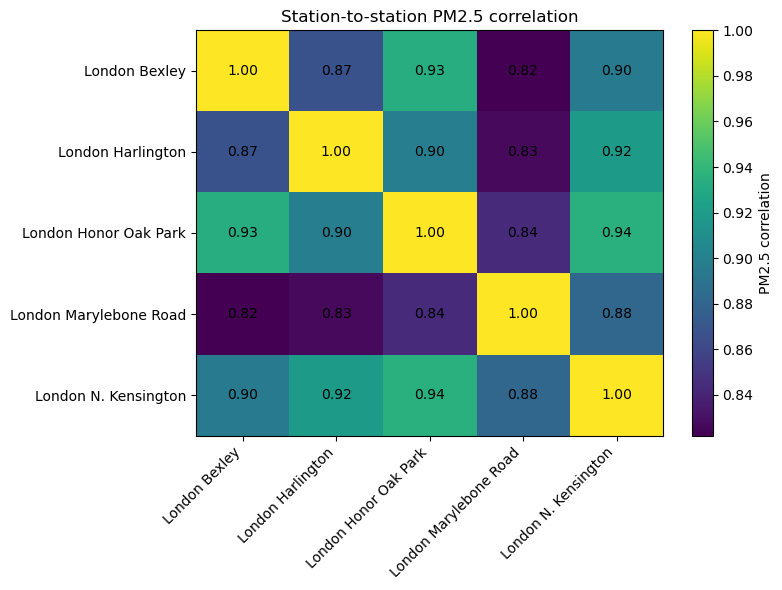

In [15]:
# ============================================================
# Step 5.1: Visualise station-to-station PM2.5 correlation
# ============================================================

# A heatmap makes the spatial correlation structure easier to inspect.
# Stronger correlations suggest that station values may be useful as neighbour-based predictors.

plt.figure(figsize=(8, 6))

plt.imshow(station_corr, aspect="auto")

plt.xticks(
    ticks=np.arange(len(station_corr.columns)),
    labels=station_corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(station_corr.index)),
    labels=station_corr.index
)

plt.colorbar(label="PM2.5 correlation")
plt.title("Station-to-station PM2.5 correlation")

for i in range(station_corr.shape[0]):
    for j in range(station_corr.shape[1]):
        value = station_corr.iloc[i, j]
        plt.text(j, i, f"{value:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()

### Step 5 interpretation

Station-to-station PM2.5 correlations are strong across the selected monitoring network. All pairwise correlations are above 0.82, showing that PM2.5 patterns move together across stations.

The strongest correlations are between London Honor Oak Park and London N. Kensington, and between London Bexley and London Honor Oak Park. London Marylebone Road has slightly lower correlations with the other stations, which may reflect its Urban Traffic site type and more localised pollution behaviour.

These results support the use of neighbouring station values as spatial predictors in later imputation models. However, correlation alone does not show physical proximity, so the next step is to calculate station distances and identify nearest neighbours.

## Step 6: Station distance matrix and nearest neighbours

This step calculates the physical distance between monitoring stations using latitude and longitudeL later spatial features should be based on a clear definition of neighbouring stations.

Station-to-station correlation showed that PM2.5 values move together across the network. Distance analysis adds the spatial part by identifying which stations are geographically closest. Together, correlation and distance support the use of neighbouring station features and inverse-distance weighting in later imputation models.

In [16]:
# ============================================================
# Step 6: Calculate station distance matrix
# ============================================================

# Physical distance is calculated because spatial imputation assumes that nearby stations
# may provide useful information when the target station has missing PM2.5 values.
# Using coordinates makes neighbour selection transparent and reproducible.

def haversine_distance_km(lat1, lon1, lat2, lon2):
    """
    Calculate the great-circle distance between two points on Earth.
    Inputs are latitude and longitude in decimal degrees.
    Output is distance in kilometres.
    """
    earth_radius_km = 6371

    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)

    lat_diff = lat2_rad - lat1_rad
    lon_diff = lon2_rad - lon1_rad

    a = (
        np.sin(lat_diff / 2) ** 2
        + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(lon_diff / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return earth_radius_km * c


stations = metadata["Station"].tolist()

distance_matrix = pd.DataFrame(
    index=stations,
    columns=stations,
    dtype=float
)

# A full pairwise distance matrix helps identify the nearest stations for every target site.
for station_a in stations:
    lat_a = metadata.loc[metadata["Station"] == station_a, "Latitude"].iloc[0]
    lon_a = metadata.loc[metadata["Station"] == station_a, "Longitude"].iloc[0]

    for station_b in stations:
        lat_b = metadata.loc[metadata["Station"] == station_b, "Latitude"].iloc[0]
        lon_b = metadata.loc[metadata["Station"] == station_b, "Longitude"].iloc[0]

        distance_matrix.loc[station_a, station_b] = haversine_distance_km(
            lat_a, lon_a, lat_b, lon_b
        )

# Rounded distances are easier to inspect and report.
display(distance_matrix.round(2))

,London Bexley,London Harlington,London Honor Oak Park,London Marylebone Road,London N. Kensington
London Bexley,0.00,43.46,15.50,24.32,28.24
London Harlington,43.46,0.00,28.33,20.22,16.20
London Honor Oak Park,15.50,28.33,0.00,11.47,14.54
London Marylebone Road,24.32,20.22,11.47,0.00,4.07
London N. Kensington,28.24,16.20,14.54,4.07,0.00


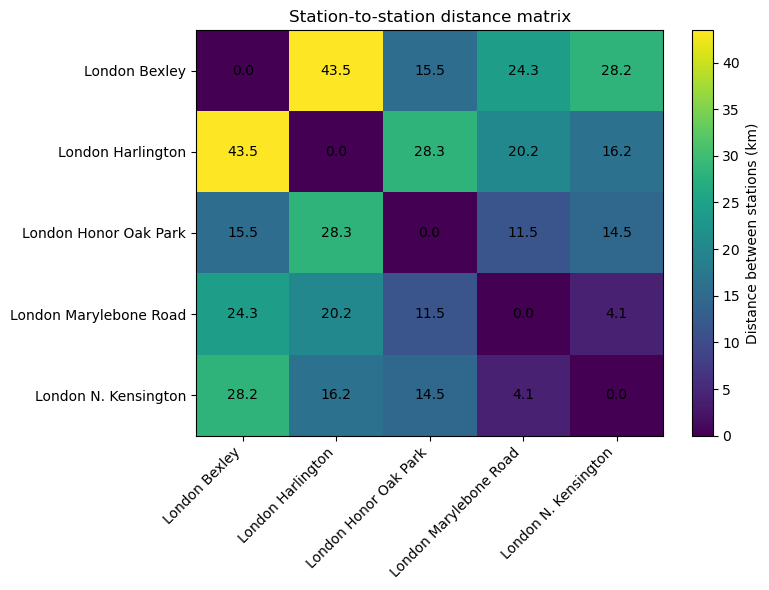

In [17]:
# ============================================================
# Step 6.1: Visualise station distance matrix
# ============================================================

# A distance heatmap makes the spatial layout easier to understand.
# Shorter distances indicate stronger candidates for nearest-neighbour features.

plt.figure(figsize=(8, 6))

plt.imshow(distance_matrix, aspect="auto")

plt.xticks(
    ticks=np.arange(len(distance_matrix.columns)),
    labels=distance_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(distance_matrix.index)),
    labels=distance_matrix.index
)

plt.colorbar(label="Distance between stations (km)")
plt.title("Station-to-station distance matrix")

for i in range(distance_matrix.shape[0]):
    for j in range(distance_matrix.shape[1]):
        value = distance_matrix.iloc[i, j]
        plt.text(j, i, f"{value:.1f}", ha="center", va="center")

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# Step 6.2: Identify nearest neighbours for each station
# ============================================================

# Nearest neighbours are identified because later spatial features can use the closest
# stations as predictors when imputing missing PM2.5 at a target station.
# The target station itself is excluded because a station should not be used as its own neighbour.

nearest_neighbour_records = []

for target_station in stations:
    distances = distance_matrix.loc[target_station].drop(target_station)
    nearest_distances = distances.sort_values()

    for rank, (neighbour_station, distance_km) in enumerate(nearest_distances.items(), start=1):
        nearest_neighbour_records.append({
            "Target_station": target_station,
            "Neighbour_rank": rank,
            "Neighbour_station": neighbour_station,
            "Distance_km": round(distance_km, 2)
        })

nearest_neighbours = pd.DataFrame(nearest_neighbour_records)

display(nearest_neighbours)

,Target_station,Neighbour_rank,Neighbour_station,Distance_km
0,London Bexley,1,London Honor Oak Park,15.50
1,London Bexley,2,London Marylebone Road,24.32
2,London Bexley,3,London N. Kensington,28.24
3,London Bexley,4,London Harlington,43.46
4,London Harlington,1,London N. Kensington,16.20
5,London Harlington,2,London Marylebone Road,20.22
6,London Harlington,3,London Honor Oak Park,28.33
7,London Harlington,4,London Bexley,43.46
8,London Honor Oak Park,1,London Marylebone Road,11.47
9,London Honor Oak Park,2,London N. Kensington,14.54


In [19]:
# ============================================================
# Step 6.3: Top 3 nearest neighbours for spatial feature design
# ============================================================

# A top-3 neighbour table is useful because later models may use k=3 nearest stations
# to create spatial predictors. This keeps the feature set small while still using
# information from multiple nearby monitoring sites.

top3_neighbours = nearest_neighbours[
    nearest_neighbours["Neighbour_rank"] <= 3
].copy()

display(top3_neighbours)

,Target_station,Neighbour_rank,Neighbour_station,Distance_km
0,London Bexley,1,London Honor Oak Park,15.50
1,London Bexley,2,London Marylebone Road,24.32
2,London Bexley,3,London N. Kensington,28.24
4,London Harlington,1,London N. Kensington,16.20
5,London Harlington,2,London Marylebone Road,20.22
6,London Harlington,3,London Honor Oak Park,28.33
8,London Honor Oak Park,1,London Marylebone Road,11.47
9,London Honor Oak Park,2,London N. Kensington,14.54
10,London Honor Oak Park,3,London Bexley,15.50
12,London Marylebone Road,1,London N. Kensington,4.07


In [20]:
# ============================================================
# Step 6.4: Inverse-distance weights for top 3 neighbours
# ============================================================

# Inverse-distance weighting gives closer neighbours more influence than farther neighbours.
# This is useful for later spatial features because it converts station distance into
# a transparent weighting rule.

idw_weights = top3_neighbours.copy()

idw_weights["Inverse_distance"] = 1 / idw_weights["Distance_km"]

idw_weights["IDW_weight"] = (
    idw_weights.groupby("Target_station")["Inverse_distance"]
    .transform(lambda x: x / x.sum())
)

idw_weights["IDW_weight"] = idw_weights["IDW_weight"].round(3)

display(
    idw_weights[
        ["Target_station", "Neighbour_rank", "Neighbour_station", "Distance_km", "IDW_weight"]
    ]
)

,Target_station,Neighbour_rank,Neighbour_station,Distance_km,IDW_weight
0,London Bexley,1,London Honor Oak Park,15.50,0.457
1,London Bexley,2,London Marylebone Road,24.32,0.292
2,London Bexley,3,London N. Kensington,28.24,0.251
4,London Harlington,1,London N. Kensington,16.20,0.421
5,London Harlington,2,London Marylebone Road,20.22,0.338
6,London Harlington,3,London Honor Oak Park,28.33,0.241
8,London Honor Oak Park,1,London Marylebone Road,11.47,0.395
9,London Honor Oak Park,2,London N. Kensington,14.54,0.312
10,London Honor Oak Park,3,London Bexley,15.50,0.293
12,London Marylebone Road,1,London N. Kensington,4.07,0.643


In [21]:
# ============================================================
# Step 6.5: Save nearest-neighbour and IDW tables
# ============================================================

# These files are saved because they will be reused later when constructing
# spatial features for the modelling datasets.

top3_neighbours.to_csv(DATA_DIR / "top3_nearest_neighbours.csv", index=False)
idw_weights.to_csv(DATA_DIR / "top3_idw_weights.csv", index=False)

print("Saved top3_nearest_neighbours.csv")
print("Saved top3_idw_weights.csv")

Saved top3_nearest_neighbours.csv
Saved top3_idw_weights.csv


### Step 6 interpretation

The distance matrix shows clear spatial relationships between the selected stations. The closest pair is London Marylebone Road and London N. Kensington, separated by only 4.07 km. Other nearby relationships include London Honor Oak Park with London Marylebone Road and London N. Kensington.

The nearest-neighbour table provides a transparent basis for later spatial feature engineering. For each target station, the three closest stations can be used as neighbouring predictors. The inverse-distance weights also give more importance to closer stations, which supports the later use of inverse-distance weighted PM2.5 features.

Together with the strong station-to-station correlations found earlier, these results support using neighbouring station values and IDW-based spatial predictors in the imputation models.

## Step 7: Train-validation-test split check

This step checks the planned chronological modelling split. A time-based split is used instead of a random split because random splitting would allow information from future periods to leak into training.

The aim is to confirm that the train, validation and test periods have the expected row counts, station coverage, PM2.5 availability and temperature availability before feature engineering and modelling.

In [22]:
# ============================================================
# Step 7: Create chronological split labels
# ============================================================

# The split is based on RawYear because annual capture and dataset selection
# were also based on RawYear. This avoids confusion caused by hour-ending timestamps
# where 24:00 is shifted to the next calendar day.
split_check = eda.copy()

def assign_split(raw_year):
    if raw_year in [2021, 2022, 2023]:
        return "Train"
    elif raw_year == 2024:
        return "Validation"
    elif raw_year == 2025:
        return "Test"
    else:
        return "Outside split"

split_check["Split"] = split_check["RawYear"].apply(assign_split)

# This confirms that all rows belong to the planned modelling periods.
display(split_check["Split"].value_counts())

Split
Train         131400
Validation     43920
Test           43800
Name: count, dtype: int64

In [23]:
# ============================================================
# Step 7.1: Row counts by split
# ============================================================

# Row counts are checked to confirm that the chronological split contains
# the expected number of hourly observations for all selected stations.
split_row_counts = (
    split_check.groupby("Split")
    .agg(
        Start_year=("RawYear", "min"),
        End_year=("RawYear", "max"),
        Total_rows=("PM25", "size"),
        Stations=("Station", "nunique")
    )
    .reset_index()
)

split_order = ["Train", "Validation", "Test"]

split_row_counts["Split"] = pd.Categorical(
    split_row_counts["Split"],
    categories=split_order,
    ordered=True
)

split_row_counts = split_row_counts.sort_values("Split")

display(split_row_counts)

,Split,Start_year,End_year,Total_rows,Stations
1,Train,2021,2023,131400,5
2,Validation,2024,2024,43920,5
0,Test,2025,2025,43800,5


In [24]:
# ============================================================
# Step 7.2: Station coverage by split
# ============================================================

# This table checks whether every station is represented equally in each split.
# Balanced station coverage is important because later model evaluation should not
# be biased by missing station-years.
split_station_counts = (
    split_check.groupby(["Split", "Station"])
    .agg(
        Rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum())
    )
    .reset_index()
)

split_station_counts["PM25_capture_%"] = round(
    split_station_counts["PM25_valid"] / split_station_counts["Rows"] * 100,
    2
)

split_station_counts["Split"] = pd.Categorical(
    split_station_counts["Split"],
    categories=split_order,
    ordered=True
)

split_station_counts = split_station_counts.sort_values(["Split", "Station"])

display(split_station_counts)

,Split,Station,Rows,PM25_valid,PM25_missing,PM25_capture_%
5,Train,London Bexley,26280,26205,75,99.71
6,Train,London Harlington,26280,26146,134,99.49
7,Train,London Honor Oak Park,26280,25883,397,98.49
8,Train,London Marylebone Road,26280,23179,3101,88.20
9,Train,London N. Kensington,26280,26099,181,99.31
10,Validation,London Bexley,8784,8772,12,99.86
11,Validation,London Harlington,8784,8756,28,99.68
12,Validation,London Honor Oak Park,8784,8749,35,99.60
13,Validation,London Marylebone Road,8784,8292,492,94.40
14,Validation,London N. Kensington,8784,8751,33,99.62


In [25]:
# ============================================================
# Step 7.3: PM2.5 and temperature availability by split
# ============================================================

# Availability is checked separately for PM2.5 and temperature because PM2.5 is the
# target variable, while temperature is an auxiliary predictor.
# This helps identify whether one split is more incomplete than the others.
split_missingness = (
    split_check.groupby("Split")
    .agg(
        Total_rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum()),
        Temperature_valid=("Temperature", lambda x: x.notna().sum()),
        Temperature_missing=("Temperature", lambda x: x.isna().sum())
    )
    .reset_index()
)

split_missingness["PM25_capture_%"] = round(
    split_missingness["PM25_valid"] / split_missingness["Total_rows"] * 100,
    2
)

split_missingness["Temperature_capture_%"] = round(
    split_missingness["Temperature_valid"] / split_missingness["Total_rows"] * 100,
    2
)

split_missingness["Split"] = pd.Categorical(
    split_missingness["Split"],
    categories=split_order,
    ordered=True
)

split_missingness = split_missingness.sort_values("Split")

display(split_missingness)

,Split,Total_rows,PM25_valid,PM25_missing,Temperature_valid,Temperature_missing,PM25_capture_%,Temperature_capture_%
1,Train,131400,127512,3888,128880,2520,97.04,98.08
2,Validation,43920,43320,600,43320,600,98.63,98.63
0,Test,43800,43181,619,42720,1080,98.59,97.53


In [26]:
# ============================================================
# Step 7.4: PM2.5 distribution by split
# ============================================================

# PM2.5 distribution is checked by split because validation and test performance
# should be interpreted in relation to the pollution levels in those periods.
# If one split contains much higher PM2.5 values, it may be more difficult to impute.
split_pm25_distribution = (
    split_check.groupby("Split")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95)),
        Max_PM25=("PM25", "max")
    )
    .reset_index()
)

split_pm25_distribution["Split"] = pd.Categorical(
    split_pm25_distribution["Split"],
    categories=split_order,
    ordered=True
)

split_pm25_distribution = split_pm25_distribution.sort_values("Split")

numeric_cols = ["Mean_PM25", "Median_PM25", "P95_PM25", "Max_PM25"]
split_pm25_distribution[numeric_cols] = split_pm25_distribution[numeric_cols].round(2)

display(split_pm25_distribution)

,Split,Observed_PM25,Mean_PM25,Median_PM25,P95_PM25,Max_PM25
1,Train,127512,8.76,6.62,22.55,133.87
2,Validation,43320,7.72,5.94,20.38,121.32
0,Test,43181,9.20,6.32,26.79,85.19


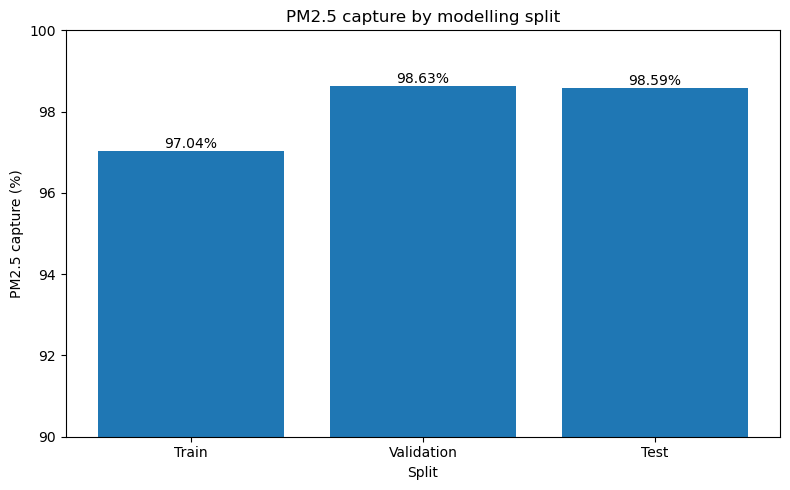

In [27]:
# ============================================================
# Step 7.5: Visualise PM2.5 capture by split
# ============================================================

# This figure checks whether the target variable is similarly available across
# train, validation and test periods.
plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_missingness["Split"].astype(str),
    split_missingness["PM25_capture_%"]
)

plt.xlabel("Split")
plt.ylabel("PM2.5 capture (%)")
plt.title("PM2.5 capture by modelling split")

plt.ylim(90, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# Step 7.6: Basic validation checks for chronological split
# ============================================================

# These checks make the split reproducible and help catch accidental leakage
# before moving to feature engineering and modelling.

assert set(split_check["Split"].unique()) == {"Train", "Validation", "Test"}, \
    "Unexpected split label found"

assert split_check[split_check["Split"] == "Train"]["RawYear"].isin([2021, 2022, 2023]).all(), \
    "Train split contains unexpected years"

assert split_check[split_check["Split"] == "Validation"]["RawYear"].eq(2024).all(), \
    "Validation split contains unexpected years"

assert split_check[split_check["Split"] == "Test"]["RawYear"].eq(2025).all(), \
    "Test split contains unexpected years"

assert split_station_counts.groupby("Split")["Station"].nunique().eq(5).all(), \
    "Not all splits contain all five stations"

print("Chronological split validation passed.")

Chronological split validation passed.


C:\Users\Msi\AppData\Local\Temp\ipykernel_7848\3706185080.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  assert split_station_counts.groupby("Split")["Station"].nunique().eq(5).all(), \


### Step 7 interpretation

The chronological train-validation-test split is valid. The training set covers 2021–2023 with 131,400 rows, the validation set covers 2024 with 43,920 rows, and the test set covers 2025 with 43,800 rows. All three splits contain the same five monitoring stations.

PM2.5 availability is high in all splits. Capture is 97.04% in training, 98.63% in validation and 98.59% in testing. Temperature availability is also high, remaining above 97% in every split. This supports the use of both PM2.5 and temperature in later modelling.

The PM2.5 distribution differs slightly between splits. The test set has the highest mean PM2.5 and the highest 95th percentile, so test performance may be slightly more challenging to interpret than validation performance. London Marylebone Road remains the weakest station in terms of PM2.5 capture, especially in training, so station-level model results should also be reported later.

Overall, the split is suitable for leakage-aware modelling because training uses earlier years, validation uses the following year, and testing is reserved for the final year.